# Predicting Retail Food Prices in Rwanda

## Use case
**Who uses the prediction:** agricultural planners, NGOs and smallholder farmers.

**What for:** estimating the expected retail price per kilogram of a food item in a given market and month, so users can judge whether a price is fair, decide where and when to sell or buy, and spot markets that look unusually expensive.

**Link to mission:** [add one sentence connecting this use case to your mission, e.g. improving food access and income for farmers].

## Dataset
WFP Rwanda Food Prices, from the Humanitarian Data Exchange (HDX): https://data.humdata.org/dataset/wfp-food-prices-for-rwanda

The file has 152,701 rows (January 2000 to July 2026) and 16 columns, a mix of numeric columns (latitude, longitude, price, plus year and month derived from the date) and categorical columns (region, market, commodity category, commodity, price type). One row is blank, leaving 152,700 usable rows. The target is `price`, a continuous number in Rwandan francs (RWF).

In [1]:
!pip install -q scikit-learn==1.9.1 joblib==1.6.0
import sklearn
print(sklearn.__version__)

1.9.1


### Load the data
The CSV (`wfp_food_prices_rwa.csv`) was downloaded from the HDX link above and uploaded to the Colab session at `/content/`. To rerun this notebook, download the same file from HDX and place it at that path.

In [2]:
import pandas as pd

df = pd.read_csv("/content/wfp_food_prices_rwa.csv")
print(df.shape)
df.info()

(157793, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157793 entries, 0 to 157792
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          157793 non-null  object 
 1   admin1        157793 non-null  object 
 2   admin2        157793 non-null  object 
 3   market        157793 non-null  object 
 4   market_id     157793 non-null  int64  
 5   latitude      157793 non-null  float64
 6   longitude     157793 non-null  float64
 7   category      157793 non-null  object 
 8   commodity     157793 non-null  object 
 9   commodity_id  157793 non-null  int64  
 10  unit          157793 non-null  object 
 11  priceflag     157793 non-null  object 
 12  pricetype     157793 non-null  object 
 13  currency      157793 non-null  object 
 14  price         157793 non-null  float64
 15  usdprice      157793 non-null  float64
dtypes: float64(4), int64(2), object(10)
memory usage: 19.3+ MB


In [3]:

print(df[df["market"].isna()])

print(df["currency"].value_counts())
print(df["priceflag"].value_counts())
print(df["pricetype"].value_counts())
print(df["unit"].value_counts())
print(df["admin1"].nunique(), "admin1")
print(df["admin2"].nunique(), "admin2")
print(df["market"].nunique(), "markets")
print(df["commodity"].nunique(), "commodities")
print(df["category"].nunique(), "categories")

Empty DataFrame
Columns: [date, admin1, admin2, market, market_id, latitude, longitude, category, commodity, commodity_id, unit, priceflag, pricetype, currency, price, usdprice]
Index: []
currency
RWF    157793
Name: count, dtype: int64
priceflag
actual              148105
actual,aggregate      6520
aggregate             3168
Name: count, dtype: int64
pricetype
Retail       157124
Wholesale       669
Name: count, dtype: int64
unit
KG      138579
Unit     10485
L         5930
Sack      2799
Name: count, dtype: int64
5 admin1
29 admin2
109 markets
65 commodities
8 categories


In [4]:
df = df.dropna(subset=["market", "price"]).copy()
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

print(df.shape)
print(df["date"].min(), "to", df["date"].max())
print(df["price"].describe())

(157793, 18)
2000-01-15 00:00:00 to 2026-08-15 00:00:00
count    157793.000000
mean       1650.792570
std        9172.719674
min          11.000000
25%         250.000000
50%         437.000000
75%         824.000000
max      332333.330000
Name: price, dtype: float64


In [5]:
print(df.groupby("unit")["price"].describe())
print(df.sort_values("price", ascending=False)[["date", "market", "commodity", "unit", "price"]].head(10))

         count          mean           std     min     25%     50%        75%  \
unit                                                                            
KG    138579.0    608.586140    631.693858   11.00   250.0   408.5    700.000   
L       5930.0   1598.130170   1066.221328  106.75   400.0  1600.0   2461.875   
Sack    2799.0   5478.553030   1222.581123  450.00  4652.5  5600.0   6333.330   
Unit   10485.0  14433.464142  32838.270437   57.67   150.0  3986.6  19111.000   

            max  
unit             
KG     39956.00  
L       5886.67  
Sack   10000.00  
Unit  332333.33  
            date     market           commodity  unit      price
24793 2011-12-15    Kamembe  Livestock (cattle)  Unit  332333.33
42250 2012-11-15   Bugarama  Livestock (cattle)  Unit  313750.00
24681 2011-12-15   Bugarama  Livestock (cattle)  Unit  310000.00
47623 2013-03-15    Kamembe  Livestock (cattle)  Unit  309375.00
46129 2013-02-15   Bugarama  Livestock (cattle)  Unit  308750.00
42353 2012-11-1

In [6]:
df = df[df["unit"] == "KG"].copy()
print(df.shape)
print(df["price"].describe())
print(df["commodity"].nunique(), "commodities left")

(138579, 18)
count    138579.000000
mean        608.586140
std         631.693858
min          11.000000
25%         250.000000
50%         408.500000
75%         700.000000
max       39956.000000
Name: price, dtype: float64
54 commodities left


In [7]:
print(df.sort_values("price", ascending=False)[["date", "market", "commodity", "price"]].head(10))
print(df["price"].quantile([0.5, 0.9, 0.99, 0.999, 0.9999]))
print(df.groupby("commodity")["price"].mean().sort_values(ascending=False).head(10))

             date          market               commodity     price
86447  2014-10-15          Byumba             Meat (goat)  39956.00
130017 2019-10-15  Gihembe (Camp)  Maize flour (imported)   9350.00
157577 2026-06-15   Kigeme (Camp)         Rice (imported)   8017.78
146855 2026-01-15         Karongi             Meat (beef)   8000.00
148100 2026-07-15          Mubuga             Meat (beef)   8000.00
148017 2026-07-15       Gasarenda             Meat (beef)   8000.00
147756 2026-06-15      Nyakarambi             Meat (beef)   8000.00
147603 2026-05-15         Karongi             Meat (beef)   8000.00
147348 2026-04-15         Karongi             Meat (beef)   8000.00
148064 2026-07-15         Karongi             Meat (beef)   8000.00
0.5000     408.5
0.9000    1250.0
0.9900    3000.0
0.9990    6000.0
0.9999    7500.0
Name: price, dtype: float64
commodity
Garlic             2538.581154
Fish (dry)         2527.562016
Apples (red)       2490.036907
Meat (goat)        2476.118393
Meat 

In [8]:
drop_cols = ["usdprice", "currency", "priceflag", "market_id",
             "commodity_id", "unit", "date", "admin2"]
df = df.drop(columns=drop_cols)

print(df.columns.tolist())
print(df.shape)

['admin1', 'market', 'latitude', 'longitude', 'category', 'commodity', 'pricetype', 'price', 'year', 'month']
(138579, 10)


In [9]:
df = df[df["price"] < 20000].copy()
print(df.shape)

(138578, 10)


### Data cleaning decisions
- **Removed one blank row** (dated 2024-12-15) that had no market or price.
- **Kept only prices per KG** (134,088 of 152,700 rows). The data mixes units (KG, litre, sack and "Unit"), and prices in different units are not comparable. Items sold per "Unit", such as livestock, reached over 300,000 RWF and would have dominated the MSE. The use case is therefore "retail price per kilogram".
- **Removed one outlier:** goat meat in Byumba (October 2014) at 39,956 RWF/kg. Goat meat averages about 2,476 RWF/kg across the data and the next-highest price is 9,350, so this was a data-entry error. Other high prices, such as beef at 8,000 or imported maize flour in camp markets, repeat across several markets and months, so they are real and were kept.

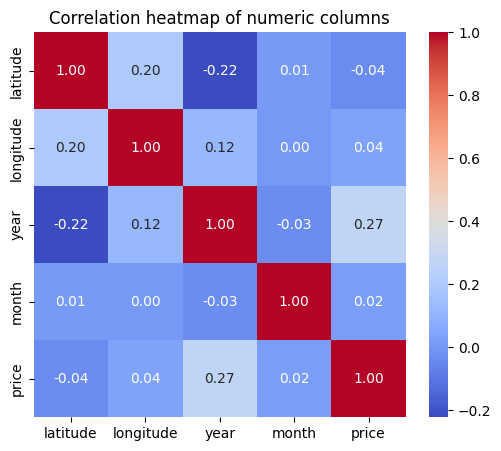

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["latitude", "longitude", "year", "month", "price"]
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap of numeric columns")
plt.show()

**What it shows:** every numeric column has a weak linear correlation with price. `year` is the strongest at 0.25, while `latitude` (-0.03), `longitude` (0.04) and `month` (0.02) are close to zero.

**What I decided:** keep `year` and `month` as inputs. The coordinates add almost nothing numerically and are already captured by `market`, so I dropped them. The heatmap cannot show categorical columns, so I checked `commodity` separately in the bar chart below.

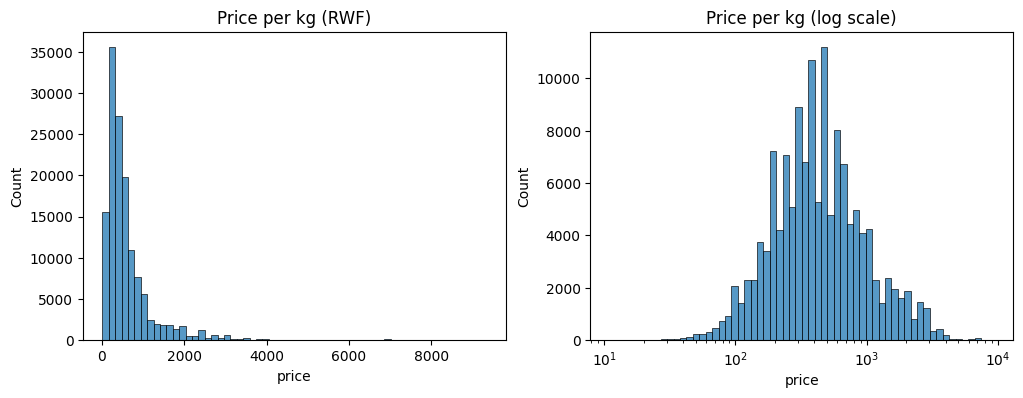

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=axes[0])
axes[0].set_title("Price per kg (RWF)")
sns.histplot(df["price"], bins=60, log_scale=True, ax=axes[1])
axes[1].set_title("Price per kg (log scale)")
plt.show()

**What it shows:** raw prices are heavily right-skewed. Most values are under 1,000 RWF/kg, with a long tail reaching about 9,000. On a log scale the distribution is close to a bell curve.

**What I decided:** keep the target in raw RWF so that the MSE and the API's predictions stay in units people understand. I expect the linear models to struggle with this skew and the tree-based models to handle it better.

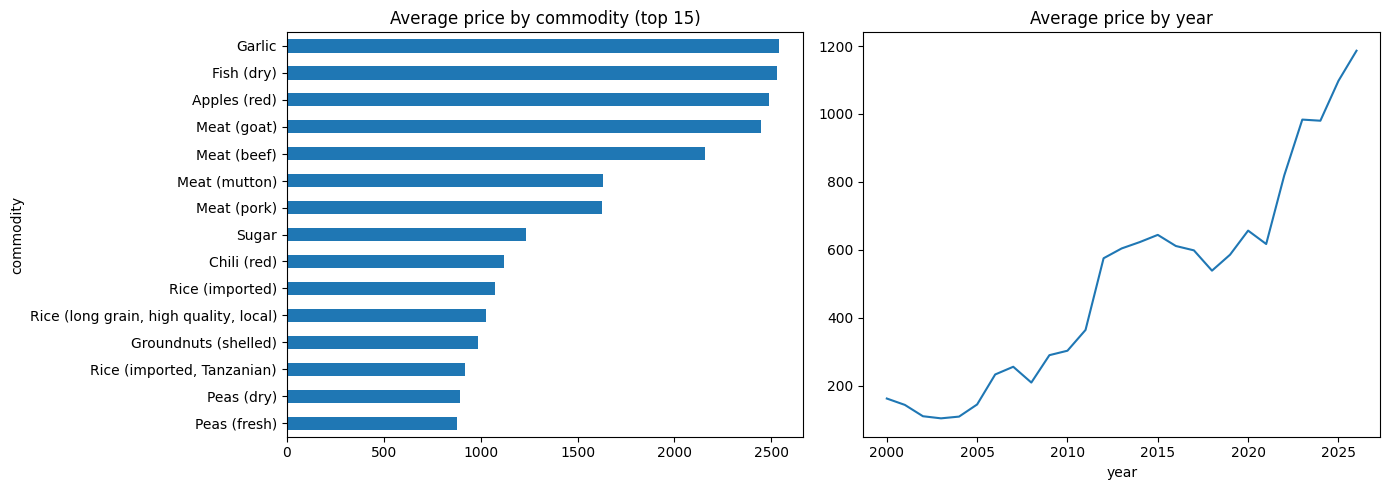

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top = df.groupby("commodity")["price"].mean().sort_values(ascending=False).head(15)
top.sort_values().plot(kind="barh", ax=axes[0], title="Average price by commodity (top 15)")
df.groupby("year")["price"].mean().plot(ax=axes[1], title="Average price by year")
plt.tight_layout()
plt.show()

**What it shows:** the average price varies a lot between commodities, from about 750 RWF/kg (imported Tanzanian rice) to about 2,500 (garlic, dried fish, apples, goat meat). Average prices were roughly flat at 100 to 200 RWF/kg until about 2005, then rose to over 1,300 by 2026.

**What I decided:** `commodity` and `year` are the most important drivers, so both must stay in the model. I also kept `market` and `pricetype`, because prices can differ between places and between retail and wholesale.

In [13]:
print(df.groupby("market")[["admin1", "latitude", "longitude"]].nunique().max())
print(df.groupby("commodity")["category"].nunique().max())

admin1       1
latitude     1
longitude    1
dtype: int64
1


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df_model = df.drop(columns=["admin1", "latitude", "longitude", "category"])

X = df_model.drop(columns="price")
y = df_model["price"]

num_features = ["year", "month"]
cat_features = ["market", "commodity", "pricetype"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print(X_train_p.shape, X_test_p.shape)

(110862, 167) (27716, 167)


### Columns dropped and why
| Column | Reason |
|---|---|
| `usdprice` | The same price in dollars, so it would leak the target |
| `currency` | Always RWF, so it carries no information |
| `priceflag` | Almost always "actual"; it describes how a price was recorded, not what drives it |
| `unit` | Constant after filtering to KG |
| `market_id`, `commodity_id` | Only codes for `market` and `commodity` |
| `date` | Replaced by two features, `year` and `month` |
| `admin2` | Overlaps with `market` |
| `admin1`, `latitude`, `longitude` | Each market has exactly one region and one pair of coordinates, so they repeat what `market` already says (checked with `groupby` above) |
| `category` | Each commodity belongs to exactly one category, so it repeats `commodity` |

**Final inputs (5):** `market`, `commodity`, `pricetype`, `year` and `month`. Fewer inputs also keep the API and the mobile app simple.

### Preparation
- **Categorical to numeric:** one-hot encoding of `market`, `commodity` and `pricetype` (unknown values are ignored at prediction time, so the API does not crash on a new market).
- **Scaling:** `StandardScaler` on `year` and `month`.
- **Split:** 80% train (107,269 rows) and 20% test (26,818 rows), giving 166 columns after encoding.
- **No leakage:** the scaler and encoder were fitted on the training set only, then applied to the test set.

In [15]:
import numpy as np
import time
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

results = {}

def evaluate(name, model):
    t = time.time()
    model.fit(X_train_p, y_train)
    tr = mean_squared_error(y_train, model.predict(X_train_p))
    te = mean_squared_error(y_test, model.predict(X_test_p))
    results[name] = (tr, te)
    print(f"{name}: train MSE {tr:,.0f} | test MSE {te:,.0f} | {time.time()-t:.0f}s")
    return model

lin = evaluate("LinearRegression", LinearRegression())
tree = evaluate("DecisionTree", DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=42))
forest = evaluate("RandomForest", RandomForestRegressor(
    n_estimators=100, max_depth=25, min_samples_leaf=5, n_jobs=-1, random_state=42))

LinearRegression: train MSE 68,845 | test MSE 65,634 | 1s
DecisionTree: train MSE 34,261 | test MSE 37,063 | 2s
RandomForest: train MSE 24,508 | test MSE 26,788 | 98s


0.0001 1e-06 67,647
0.0001 0.0001 67,757
0.0001 0.01 113,043
0.001 1e-06 65,793
0.001 0.0001 65,789
0.001 0.01 112,920
0.01 1e-06 66,782
0.01 0.0001 66,812
0.01 0.01 116,150


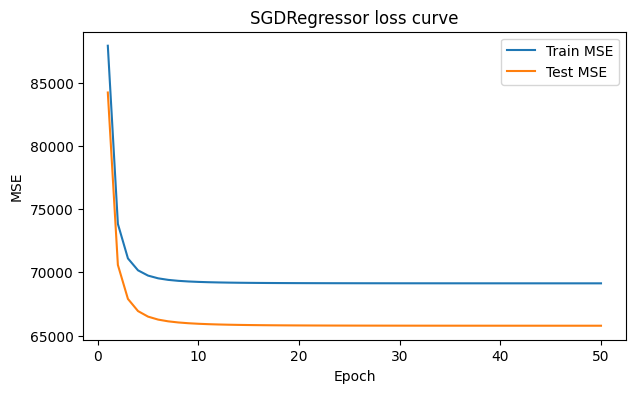

In [16]:
from sklearn.linear_model import SGDRegressor

def run_sgd(eta0, alpha, epochs=30):
    sgd = SGDRegressor(penalty="l2", alpha=alpha, learning_rate="constant",
                       eta0=eta0, random_state=42)
    train_losses, test_losses = [], []
    for _ in range(epochs):
        sgd.partial_fit(X_train_p, y_train)
        train_losses.append(mean_squared_error(y_train, sgd.predict(X_train_p)))
        test_losses.append(mean_squared_error(y_test, sgd.predict(X_test_p)))
    return sgd, train_losses, test_losses

tuning = []
for eta0 in [0.0001, 0.001, 0.01]:
    for alpha in [1e-6, 1e-4, 1e-2]:
        _, trl, tel = run_sgd(eta0, alpha)
        tuning.append({"eta0": eta0, "alpha": alpha,
                       "final_train_MSE": trl[-1], "final_test_MSE": tel[-1]})
        print(eta0, alpha, f"{tel[-1]:,.0f}")

import pandas as pd
tuning_df = pd.DataFrame(tuning).sort_values("final_test_MSE")
tuning_df
best = tuning_df.iloc[0]
sgd, train_losses, test_losses = run_sgd(best["eta0"], best["alpha"], epochs=50)
results["SGDRegressor"] = (train_losses[-1], test_losses[-1])

plt.figure(figsize=(7, 4))
plt.plot(range(1, 51), train_losses, label="Train MSE")
plt.plot(range(1, 51), test_losses, label="Test MSE")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend()
plt.title("SGDRegressor loss curve")
plt.show()

### SGDRegressor tuning and loss curve
I tried learning rates (`eta0`) of 0.0001, 0.001 and 0.01 with L2 regularization strengths (`alpha`) of 1e-6, 1e-4 and 1e-2, training 30 epochs each with `partial_fit`.
- **Regularization had the biggest effect.** With `alpha=0.01` the test MSE jumped to about 113,000 to 116,000, because strong regularization shrinks the coefficients too much. With `alpha` of 1e-6 or 1e-4 it stayed between about 65,800 and 67,800.
- **Learning rate had a small effect.** `eta0=0.0001` converged slowest and ended at about 67,650 to 67,760, `eta0=0.01` ended slightly higher than the best at about 66,800, and `eta0=0.001` gave the lowest test MSE (about 65,789 with `alpha=1e-4`).

**Loss curve:** both train and test MSE fall quickly in the first 5 to 10 epochs, then flatten. The gap between them is small and stable, so the model is not overfitting. It has reached the limit of what a straight-line model can learn from these features (underfitting).

In [17]:
comparison = pd.DataFrame(results, index=["Train MSE", "Test MSE"]).T.round(0)
comparison.sort_values("Test MSE")

,Train MSE,Test MSE
RandomForest,24508.0,26788.0
DecisionTree,34261.0,37063.0
LinearRegression,68845.0,65634.0
SGDRegressor,69134.0,65783.0


### Model comparison

**Best model: RandomForestRegressor, with the lowest test MSE (26,788).**

| Model | Train MSE | Test MSE |
|---|---|---|
| RandomForestRegressor | 24,508 | 26,788 |
| DecisionTreeRegressor | 34,261 | 37,063 |
| LinearRegression | 68,845 | 65,634 |
| SGDRegressor | 69,134 | 65,783 |

**How the dataset affected each model:**
- **Linear models (LinearRegression and SGDRegressor)** gave almost identical results. Price depends on combinations of commodity, market and year, which a straight line cannot capture, so both underfit.
- **DecisionTreeRegressor** can learn those combinations and cut the error almost in half.
- **RandomForestRegressor** averages many trees, which reduces variance. Its train and test MSE are close (24,508 vs 26,788), so it is not overfitting.

**Is the test loss high or low?** The forest's RMSE is about 164 RWF/kg, against a median price of 400 RWF/kg. That is moderate: good for cheap staples, weaker for expensive items such as meat, where a small percentage error is a large number of francs.

**How to reduce it further:** add the previous month's price for the same market and commodity, tune the forest, or train on log-transformed prices.

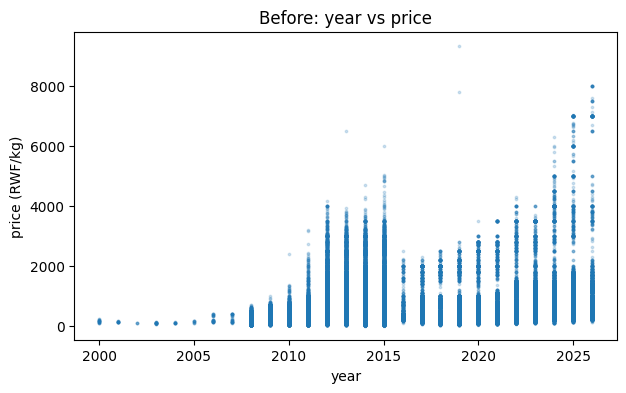

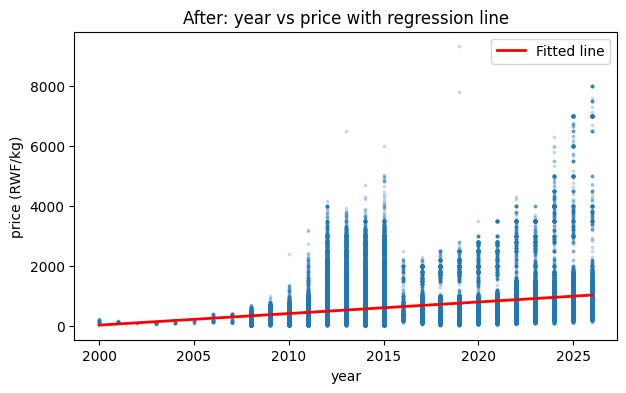

In [18]:
from sklearn.linear_model import LinearRegression

plt.figure(figsize=(7, 4))
plt.scatter(df["year"], df["price"], s=3, alpha=0.2)
plt.xlabel("year"); plt.ylabel("price (RWF/kg)")
plt.title("Before: year vs price")
plt.show()

line = LinearRegression().fit(df[["year"]], df["price"])
xs = pd.DataFrame({"year": np.arange(df["year"].min(), df["year"].max() + 1)})

plt.figure(figsize=(7, 4))
plt.scatter(df["year"], df["price"], s=3, alpha=0.2)
plt.plot(xs["year"], line.predict(xs), color="red", linewidth=2, label="Fitted line")
plt.xlabel("year"); plt.ylabel("price (RWF/kg)"); plt.legend()
plt.title("After: year vs price with regression line")
plt.show()

**Before:** `year` is the numeric feature most correlated with price. Prices rise over time, but within a single year they range from near zero to several thousand RWF/kg, so year alone explains little.

**After:** the fitted line captures the upward trend (about 50 RWF/kg in 2000 to about 1,000 in 2026) but sits at the bottom of the cloud. This shows why a one-feature linear model is not enough, and why commodity and market are needed.

### Saving the best model
The random forest is saved together with its preprocessing as a scikit-learn `Pipeline` using `joblib` (`best_model.pkl`, 7.9 MB). The API can therefore pass raw values (market, commodity, price type, year, month) straight to the model. The saved pipeline reproduces the test MSE of 26,788, and was trained with scikit-learn 1.9.1, the version locked in `uv.lock`.

In [19]:
import joblib, os, sklearn
from sklearn.pipeline import Pipeline

print("scikit-learn", sklearn.__version__)

best_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestRegressor(n_estimators=100, max_depth=25,
                                    min_samples_leaf=5, n_jobs=-1, random_state=42)),
])
best_pipeline.fit(X_train, y_train)

print("Test MSE:", mean_squared_error(y_test, best_pipeline.predict(X_test)))

joblib.dump(best_pipeline, "best_model.pkl", compress=3)
print(f"{os.path.getsize('best_model.pkl') / 1e6:.1f} MB")

scikit-learn 1.9.1
Test MSE: 26787.681929851125
7.9 MB


In [20]:
def predict_price(row: dict, model_path="best_model.pkl"):
    model = joblib.load(model_path)
    X_row = pd.DataFrame([row])
    return float(model.predict(X_row)[0])

sample = X_test.iloc[0].to_dict()
print(sample)
print("Predicted:", predict_price(sample), "| Actual:", y_test.iloc[0])

{'market': 'Kiziba (Camp)', 'commodity': 'Potatoes', 'pricetype': 'Retail', 'year': 2018, 'month': 9}
Predicted: 390.14105082705214 | Actual: 125.0


commodity    0.813812
year         0.155473
market       0.018703
month        0.012007
pricetype    0.000005
dtype: float64


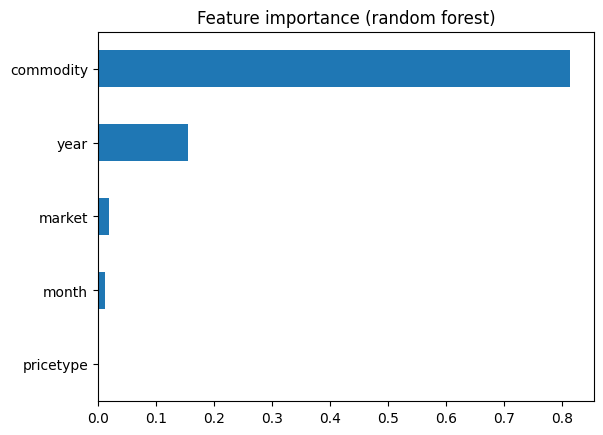

In [21]:
feature_names = preprocessor.get_feature_names_out()
importances = pd.Series(best_pipeline.named_steps["model"].feature_importances_, index=feature_names)

def base_feature(name):
    name = name.split("__", 1)[1]
    for f in ["market", "commodity", "pricetype", "year", "month"]:
        if name == f or name.startswith(f + "_"):
            return f
    return name

grouped = importances.groupby(base_feature).sum().sort_values(ascending=False)
print(grouped)
grouped.sort_values().plot(kind="barh", title="Feature importance (random forest)")
plt.show()

### Which features matter most
The chart above adds up the random forest's importance for each original feature (all one-hot columns of a feature are combined).

| Feature | Importance |
|---|---|
| `commodity` | 0.814 |
| `year` | 0.155 |
| `market` | 0.019 |
| `month` | 0.012 |
| `pricetype` | 0.000 |

**`commodity` is by far the most important feature (about 81% of the total), followed by `year` (about 16%).** Which food item is being sold explains most of the price, and the year captures the long-term rise in prices. `market` (about 2%) and `month` (about 1%) add a little, for example for regional differences and seasonal changes. `pricetype` has almost no importance, because 99.6% of the rows are retail prices, so the model has almost nothing to learn from it.

This matches the earlier plots: the commodity bar chart showed a large spread between items, and the year chart showed a clear upward trend.